In [6]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

# PERGUNTA DE NEGÓCIO
# Existem diferenças nos preços das roupas masculinas e dos acessórios
# vendidos na SHEIN, e como a limpeza dos dados pode ajudar a comparar
# essas categorias de forma confiável?

# CARREGAMENTO DOS ARQUIVOS
masculino = pd.read_csv(
    '/content/us-shein-mens_clothes-1891.csv'
)

acessorios = pd.read_csv(
    '/content/us-shein-jewelry_and_accessories-3548.csv'
)

# VERIFICANDO DIMENSÕES
print("Roupas masculinas:", masculino.shape)
print("Acessórios:", acessorios.shape)

Roupas masculinas: (1890, 7)
Acessórios: (3547, 8)


In [7]:
# DIAGNÓSTICO INICIAL

print("=== ROUPAS MASCULINAS ===")
masculino.info()

print("\nValores ausentes:")
print(masculino.isnull().sum())

print("\nLinhas duplicadas:", masculino.duplicated().sum())

print("\nPrimeiras linhas:")
display(masculino.head())

print("\n=== ACESSÓRIOS ===")
acessorios.info()

print("\nValores ausentes:")
print(acessorios.isnull().sum())

print("\nLinhas duplicadas:", acessorios.duplicated().sum())

print("\nPrimeiras linhas:")
display(acessorios.head())

=== ROUPAS MASCULINAS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1890 entries, 0 to 1889
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   color-count          1141 non-null   float64
 1   goods-title-link     1889 non-null   object 
 2   selling_proposition  1277 non-null   object 
 3   price                1889 non-null   object 
 4   discount             1860 non-null   object 
 5   rank-title           560 non-null    object 
 6   rank-sub             560 non-null    object 
dtypes: float64(1), object(6)
memory usage: 103.5+ KB

Valores ausentes:
color-count             749
goods-title-link          1
selling_proposition     613
price                     1
discount                 30
rank-title             1330
rank-sub               1330
dtype: int64

Linhas duplicadas: 86

Primeiras linhas:


,color-count,goods-title-link,selling_proposition,price,discount,rank-title,rank-sub
0,15.0,Manfinity Homme Loose Fit Men's Solid Color Bu...,10k+ sold recently,$11.99,-7%,NaN,NaN
1,NaN,Manfinity Joysei Men's Star Patterned Shorts W...,NaN,$11.19,-13%,#8 Best Seller,in Blue Men Clothing
2,NaN,Men's Summer Casual Short Sleeve T-Shirt With ...,NaN,$8.09,-13%,#10 Best Seller,in Figure Men T-Shirts
3,11.0,Manfinity Homme Men's Contrast Color Short Sle...,10k+ sold recently,$9.99,-12%,NaN,NaN
4,7.0,Manfinity EMRG Loose Fit Men Plus Letter Print...,30+ sold recently,$3.48,-70%,NaN,NaN



=== ACESSÓRIOS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3547 entries, 0 to 3546
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   goods-title-link--jump       39 non-null     object
 1   goods-title-link--jump href  39 non-null     object
 2   rank-title                   716 non-null    object
 3   rank-sub                     716 non-null    object
 4   price                        3547 non-null   object
 5   selling_proposition          2736 non-null   object
 6   discount                     1926 non-null   object
 7   goods-title-link             3508 non-null   object
dtypes: object(8)
memory usage: 221.8+ KB

Valores ausentes:
goods-title-link--jump         3508
goods-title-link--jump href    3508
rank-title                     2831
rank-sub                       2831
price                             0
selling_proposition             811
discount                   

,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,selling_proposition,discount,goods-title-link
0,Customized Personalized Heart-Shaped Lace Name...,https://us.shein.com/Customized-Personalized-H...,#3 Best Sellers,in Customized Fashion Word Necklaces,$6.40,NaN,NaN,NaN
1,"24pcs/Set Simple Heart, Butterfly, Flower, Rhi...",https://us.shein.com/24pcs-Set-Simple-Heart-Bu...,NaN,NaN,$2.10,7.2k+ sold recently,NaN,NaN
2,"A Multi-Functional Electronic Watch With 1.44""...",https://us.shein.com/A-Multi-Functional-Electr...,#7 Best Sellers,in Women Digital Watches,$8.20,NaN,-10%,NaN
3,91pcs/Set Fashionable Elegant Vintage Multi-El...,https://us.shein.com/91pcs-Set-Fashionable-Ele...,#9 Best Sellers,in Women Jewelry Sets,$1.50,NaN,NaN,NaN
4,Multi-pack Random Mix-color Popular Bohemian R...,https://us.shein.com/Multi-pack-Random-Mix-col...,NaN,NaN,$1.10,7.4k+ sold recently,NaN,NaN


In [8]:
# CONFERINDO OS FORMATOS DOS DADOS

print("PREÇOS — ROUPAS MASCULINAS")
print(masculino['price'].head(10).to_list())

print("\nPREÇOS — ACESSÓRIOS")
print(acessorios['price'].head(10).to_list())

print("\nDESCONTOS — ROUPAS MASCULINAS")
print(masculino['discount'].dropna().head(10).to_list())

print("\nDESCONTOS — ACESSÓRIOS")
print(acessorios['discount'].dropna().head(10).to_list())

PREÇOS — ROUPAS MASCULINAS
['$11.99', '$11.19', '$8.09', '$9.99', '$3.48', '$24.69', '$22.79', '$4.10', '$7.99', '$23.95']

PREÇOS — ACESSÓRIOS
['$6.40', '$2.10', '$8.20', '$1.50', '$1.10', '$3.00', '$2.70', '$2.80', '$3.40', '$1.40']

DESCONTOS — ROUPAS MASCULINAS
['-7%', '-13%', '-13%', '-12%', '-70%', '-12%', '-7%', '-56%', '-13%', '-14%']

DESCONTOS — ACESSÓRIOS
['-10%', '-9%', '-8%', '-8%', '-11%', '-18%', '-1%', '-50%', '-79%', '-10%']


In [9]:
# FUNÇÃO 1 — CORRIGIR TIPOS

def corrigir_tipos(df):
    df = df.copy()

    if 'price' in df.columns:
        df['price'] = pd.to_numeric(
            df['price'].astype(str)
            .str.replace('$', '', regex=False)
            .str.replace(',', '', regex=False)
            .str.strip(),
            errors='coerce'
        )

    if 'discount' in df.columns:
        df['discount'] = pd.to_numeric(
            df['discount'].astype(str)
            .str.replace('%', '', regex=False)
            .str.strip(),
            errors='coerce'
        )

    if 'color-count' in df.columns:
        df['color-count'] = pd.to_numeric(
            df['color-count'], errors='coerce'
        )

    return df


# FUNÇÃO 2 — TRATAR VALORES AUSENTES

def tratar_ausentes(df):
    df = df.copy()

    # Unificar os possíveis campos de título em uma coluna
    titulos = []

    for coluna in [
        'goods-title-link',
        'goods-title-link--jump'
    ]:
        if coluna in df.columns:
            titulos.append(df[coluna])

    if titulos:
        df['product_title'] = titulos[0]

        for titulo in titulos[1:]:
            df['product_title'] = (
                df['product_title'].fillna(titulo)
            )

        df['product_title'] = (
            df['product_title'].astype('string').str.strip()
        )

        df.loc[
            df['product_title'].eq(''),
            'product_title'
        ] = pd.NA

        # Sem título, o produto não pode ser identificado adequadamente
        df = df[df['product_title'].notna()].copy()

    # Remover preços ausentes, inválidos ou não positivos
    if 'price' in df.columns:
        df = df[
            df['price'].notna() & (df['price'] > 0)
        ].copy()

    # Ausências em desconto, classificação e vendas são preservadas.
    # Não significa que o produto tenha desconto ou venda igual a zero.

    return df


# FUNÇÃO 3 — REMOVER DUPLICATAS

def tratar_duplicatas(df):
    df = df.copy()
    return df.drop_duplicates().copy()


# FUNÇÃO 4 — PADRONIZAR TEXTOS

def padronizar_textos(df):
    df = df.copy()

    for coluna in df.select_dtypes(include=['object', 'string']).columns:
        df[coluna] = df[coluna].apply(
            lambda texto: texto.strip()
            if isinstance(texto, str)
            else texto
        )

    return df


# FUNÇÃO 5 — IDENTIFICAR OUTLIERS

def tratar_outliers(df):
    df = df.copy()

    if 'price' in df.columns and df['price'].notna().sum() > 0:
        q1 = df['price'].quantile(0.25)
        q3 = df['price'].quantile(0.75)
        iqr = q3 - q1

        limite_inferior = max(0, q1 - 1.5 * iqr)
        limite_superior = q3 + 1.5 * iqr

        df['price_outlier'] = (
            (df['price'] < limite_inferior) |
            (df['price'] > limite_superior)
        )

        print("Outliers identificados:", df['price_outlier'].sum())
        print("Limite inferior:", limite_inferior)
        print("Limite superior:", limite_superior)

    return df


# FUNÇÃO 6 — CRIAR NOVAS FEATURES

def criar_features(df):
    df = df.copy()

    if 'price' in df.columns:
        df['faixa_preco'] = pd.cut(
            df['price'],
            bins=[0, 5, 15, 30, np.inf],
            labels=[
                'Baixo (até US$ 5)',
                'Médio (US$ 5 a 15)',
                'Alto (US$ 15 a 30)',
                'Muito alto (acima de US$ 30)'
            ],
            include_lowest=True
        )

    if 'discount' in df.columns:
        df['tem_desconto'] = df['discount'].notna()

    return df


print("Todas as funções foram criadas!")

Todas as funções foram criadas!


In [10]:
# EXECUÇÃO DO PIPELINE

# Preservando os dados originais
masculino_original = masculino.copy()
acessorios_original = acessorios.copy()


def executar_pipeline(df):
    df = corrigir_tipos(df)
    df = tratar_ausentes(df)
    df = tratar_duplicatas(df)
    df = padronizar_textos(df)
    df = tratar_outliers(df)
    df = criar_features(df)

    return df


masculino_limpo = executar_pipeline(masculino_original)
acessorios_limpos = executar_pipeline(acessorios_original)

print("Roupas masculinas após a limpeza:", masculino_limpo.shape)
print("Acessórios após a limpeza:", acessorios_limpos.shape)

display(masculino_limpo.head())
display(acessorios_limpos.head())

Outliers identificados: 42
Limite inferior: 0
Limite superior: 25.152499999999996
Outliers identificados: 286
Limite inferior: 0
Limite superior: 5.5
Roupas masculinas após a limpeza: (1803, 11)
Acessórios após a limpeza: (3367, 12)


,color-count,goods-title-link,selling_proposition,price,discount,rank-title,rank-sub,product_title,price_outlier,faixa_preco,tem_desconto
0,15.0,Manfinity Homme Loose Fit Men's Solid Color Bu...,10k+ sold recently,11.99,-7.0,NaN,NaN,Manfinity Homme Loose Fit Men's Solid Color Bu...,False,Médio (US$ 5 a 15),True
1,NaN,Manfinity Joysei Men's Star Patterned Shorts W...,NaN,11.19,-13.0,#8 Best Seller,in Blue Men Clothing,Manfinity Joysei Men's Star Patterned Shorts W...,False,Médio (US$ 5 a 15),True
2,NaN,Men's Summer Casual Short Sleeve T-Shirt With ...,NaN,8.09,-13.0,#10 Best Seller,in Figure Men T-Shirts,Men's Summer Casual Short Sleeve T-Shirt With ...,False,Médio (US$ 5 a 15),True
3,11.0,Manfinity Homme Men's Contrast Color Short Sle...,10k+ sold recently,9.99,-12.0,NaN,NaN,Manfinity Homme Men's Contrast Color Short Sle...,False,Médio (US$ 5 a 15),True
4,7.0,Manfinity EMRG Loose Fit Men Plus Letter Print...,30+ sold recently,3.48,-70.0,NaN,NaN,Manfinity EMRG Loose Fit Men Plus Letter Print...,False,Baixo (até US$ 5),True


,goods-title-link--jump,goods-title-link--jump href,rank-title,rank-sub,price,selling_proposition,discount,goods-title-link,product_title,price_outlier,faixa_preco,tem_desconto
0,Customized Personalized Heart-Shaped Lace Name...,https://us.shein.com/Customized-Personalized-H...,#3 Best Sellers,in Customized Fashion Word Necklaces,6.4,NaN,NaN,NaN,Customized Personalized Heart-Shaped Lace Name...,True,Médio (US$ 5 a 15),False
1,"24pcs/Set Simple Heart, Butterfly, Flower, Rhi...",https://us.shein.com/24pcs-Set-Simple-Heart-Bu...,NaN,NaN,2.1,7.2k+ sold recently,NaN,NaN,"24pcs/Set Simple Heart, Butterfly, Flower, Rhi...",False,Baixo (até US$ 5),False
2,"A Multi-Functional Electronic Watch With 1.44""...",https://us.shein.com/A-Multi-Functional-Electr...,#7 Best Sellers,in Women Digital Watches,8.2,NaN,-10.0,NaN,"A Multi-Functional Electronic Watch With 1.44""...",True,Médio (US$ 5 a 15),True
3,91pcs/Set Fashionable Elegant Vintage Multi-El...,https://us.shein.com/91pcs-Set-Fashionable-Ele...,#9 Best Sellers,in Women Jewelry Sets,1.5,NaN,NaN,NaN,91pcs/Set Fashionable Elegant Vintage Multi-El...,False,Baixo (até US$ 5),False
4,Multi-pack Random Mix-color Popular Bohemian R...,https://us.shein.com/Multi-pack-Random-Mix-col...,NaN,NaN,1.1,7.4k+ sold recently,NaN,NaN,Multi-pack Random Mix-color Popular Bohemian R...,False,Baixo (até US$ 5),False


In [11]:
# TABELA ANTES X DEPOIS

def avaliar_qualidade(df):
    total_celulas = df.size

    return {
        'Quantidade de linhas': len(df),
        'Valores ausentes (%)': round(
            df.isnull().sum().sum() / total_celulas * 100, 2
        ) if total_celulas else 0,
        'Linhas duplicadas': int(df.duplicated().sum()),
        'Tipo do preço': str(
            df['price'].dtype
        ) if 'price' in df.columns else 'Não existe'
    }


comparacao = pd.DataFrame({
    'Masculino - Antes': avaliar_qualidade(masculino_original),
    'Masculino - Depois': avaliar_qualidade(masculino_limpo),
    'Acessórios - Antes': avaliar_qualidade(acessorios_original),
    'Acessórios - Depois': avaliar_qualidade(acessorios_limpos)
})

display(comparacao)

,Masculino - Antes,Masculino - Depois,Acessórios - Antes,Acessórios - Depois
Quantidade de linhas,1890,1803,3547,3367
Valores ausentes (%),30.64,19.48,53.39,35.51
Linhas duplicadas,86,0,180,0
Tipo do preço,object,float64,object,float64


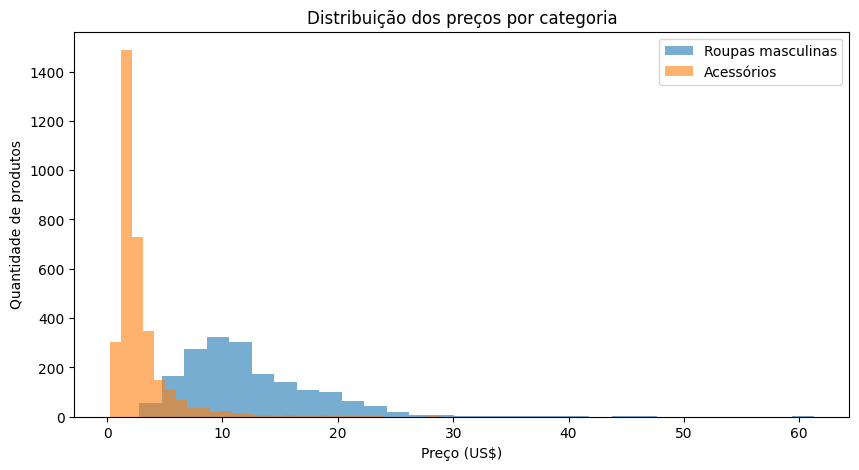

In [12]:
# DISTRIBUIÇÃO DOS PREÇOS

plt.figure(figsize=(10, 5))

plt.hist(
    masculino_limpo['price'],
    bins=30,
    alpha=0.6,
    label='Roupas masculinas'
)

plt.hist(
    acessorios_limpos['price'],
    bins=30,
    alpha=0.6,
    label='Acessórios'
)

plt.xlabel('Preço (US$)')
plt.ylabel('Quantidade de produtos')
plt.title('Distribuição dos preços por categoria')
plt.legend()
plt.show()

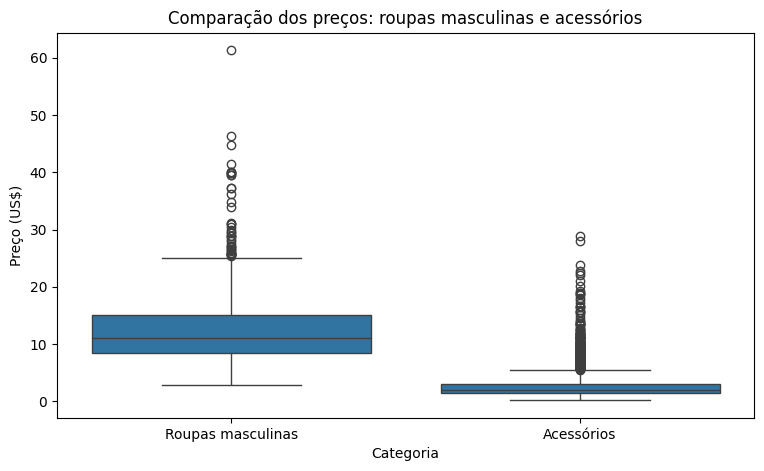

In [13]:
# COMPARAÇÃO DOS PREÇOS

precos_comparacao = pd.DataFrame({
    'Preço': pd.concat([
        masculino_limpo['price'],
        acessorios_limpos['price']
    ], ignore_index=True),

    'Categoria': (
        ['Roupas masculinas'] * len(masculino_limpo)
        + ['Acessórios'] * len(acessorios_limpos)
    )
})

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=precos_comparacao,
    x='Categoria',
    y='Preço'
)

plt.title('Comparação dos preços: roupas masculinas e acessórios')
plt.xlabel('Categoria')
plt.ylabel('Preço (US$)')
plt.show()

In [14]:
# # Relatório de Limpeza e Preparação de Dados — SHEIN

# ## 1. Objetivo

# Analisar as diferenças entre os preços das roupas masculinas e dos acessórios vendidos na SHEIN, utilizando técnicas de limpeza e preparação de dados para tornar a comparação mais confiável.

# ## 2. Dados utilizados

# Foram utilizados dois arquivos CSV:

# - `us-shein-mens_clothes-1891.csv`: roupas masculinas.
# - `us-shein-jewelry_and_accessories-3548.csv`: acessórios.

# ## 3. Etapas realizadas

# **Correção de tipos:** os preços foram convertidos de texto para números decimais. Os descontos e as contagens de cores também foram preparados para análise numérica.

# **Tratamento de valores ausentes:** os campos de título foram combinados em uma coluna padronizada. Registros sem título identificável ou sem preço válido foram removidos. Valores ausentes em descontos, classificações e outras informações opcionais foram preservados.

# **Remoção de duplicatas:** foram identificadas 86 linhas duplicadas nas roupas masculinas e 180 nos acessórios, antes da limpeza.

# **Padronização de textos:** foram removidos espaços desnecessários no início e no final dos campos textuais.

# **Tratamento de outliers:** os preços extremos foram identificados pelo método do intervalo interquartil (IQR). Os valores originais foram preservados, pois preços elevados não representam necessariamente erros.

# **Criação de features:** foi criada a coluna `faixa_preco`, que classifica os produtos em faixas de preço. Também foi criada a coluna `tem_desconto` para indicar se existe informação de desconto disponível.

# ## 4. Resultados

# A tabela de qualidade antes e depois permite comparar a quantidade de registros, os valores ausentes, as duplicatas e os tipos de dados.

# Os gráficos permitem observar a distribuição dos preços, comparar as medianas e identificar possíveis valores extremos nas duas categorias.

# ## 5. Conclusão

# O processo de limpeza melhora a consistência dos dados e facilita a comparação entre roupas masculinas e acessórios. A conversão dos preços, a remoção de duplicatas e a padronização dos títulos contribuem para uma análise mais confiável.

# As conclusões sobre qual categoria possui preços mais altos devem ser confirmadas pelos valores estatísticos e pelos gráficos gerados após a limpeza.